In [2]:
import os
import pickle
from itertools import product

import numpy as np
import matplotlib.pyplot as plt

import astropy.table as at
import astropy.units as u
import astropy.coordinates as coord
from astropy.table import Table
from astropy.coordinates import SkyCoord, Distance

import jax
import jax.numpy as jnp
import jax.random as jr

import numpyro
import numpyro.distributions as dist
import numpyro.infer as infer

from scipy.stats import binned_statistic
from scipy.optimize import brentq
from tqdm import tqdm

jax.config.update("jax_enable_x64", True)
%matplotlib inline

In [3]:
t = Table.read("astraAllStarASPCAP-0.8.fits.gz", format="fits", hdu=2)
t["sdss4_apogee_id"] = t["sdss4_apogee_id"].filled(-1)

dr17 = Table.read("allStarLite-dr17-synspec_rev1.fits", hdu=1)
t = at.join(
    t,
    dr17["APOGEE_ID", "SNR", "VHELIO_AVG"],
    keys_left="sdss4_apogee_id",
    keys_right="APOGEE_ID",
    join_type="left",
)
print("loaded t:", len(t))

from src.selection import build_prechem_selection

master_mask, sel_diag, sel_arrays = build_prechem_selection(t)
t_sel = t[master_mask]
print("pre-chem selected:", sel_diag["prechem_selected"])

loaded t: 2576187
pre-chem selected: 630079


In [4]:
from src.coords import build_galactocentric_xyz_zsun0
from src.chemistry import apply_low_alpha_cut, FEH_CUT

x, y, z = build_galactocentric_xyz_zsun0(t_sel)
chem_result = apply_low_alpha_cut(t_sel, x=x, y=y, z=z, feh_cut=FEH_CUT)

t_sel = chem_result["table"]
fe   = chem_result["fe"]
mgfe = chem_result["mgfe"]
print(f"after low-α + [Fe/H] >= {FEH_CUT}:", len(t_sel))

after low-α + [Fe/H] >= -1.2: 467098


In [5]:
feh_min_extra = -.9

extra_mask = np.asarray(fe) > feh_min_extra
t_sel = t_sel[extra_mask]
fe   = np.asarray(fe)[extra_mask]
mgfe = np.asarray(mgfe)[extra_mask]

print(f"after additional [Fe/H] > {feh_min_extra} cut:", len(t_sel))

after additional [Fe/H] > -0.9 cut: 459435


In [6]:
from src.chemistry import apply_alfe_mgmn_polygon_cut

t_final, final_diag, final_arrays = apply_alfe_mgmn_polygon_cut(t_sel)
print("t_final size:", final_diag["output_size"])

t_final size: 391384


In [7]:
from src.coords import build_star_pack_zsun0
star_pack, star_diag = build_star_pack_zsun0(t_final, rmax_keep=16, plx_min=None)

R_star    = star_pack["R_star"]
Z_star    = star_pack["Z_star"]
phi_star  = star_pack["phi_star"]
mgfe_star = star_pack["mgfe_star"]
t_star    = star_pack["t_star"]

In [8]:
from src.coords import build_segment_setup
from src.utils import col_to_float_array

segm, crowd_bounds, window_edges, seg_diag = build_segment_setup(
    phi_star, phi0=np.pi, crowd_halfwidth_deg=45, n_crowd=11
)
SEG_PLOT_heat = list(range(1, seg_diag["n_crowd"] + 1))

e_mg_h_star = col_to_float_array(t_star, "e_mg_h")
e_fe_h_star = col_to_float_array(t_star, "e_fe_h")
mgfe_err_star = np.sqrt(np.asarray(e_mg_h_star, float)**2 + np.asarray(e_fe_h_star, float)**2)

print("star_pack final size:", star_diag["final_size"])

star_pack final size: 389480


In [9]:
z_edges    = np.linspace(-3.0, 3.0, 181)
mgfe_edges = np.linspace(-0.2, 0.6, 161)
R_edges    = np.arange(0.5, 15.5 + 0.5, 0.5)

minN_seg_total   = 15
min_bin_count    = 5
min_bins_for_fit = 8
z_fit_min, z_fit_max = -1.5, 1.5
zlim = 0.6

R_centers = 0.5 * (R_edges[:-1] + R_edges[1:])

In [10]:
def single_sech2(z, A1, h1, z0):
    dz = z - z0
    return A1 * (1 / jnp.cosh(dz / h1)) ** 2

def model(data):
    _A1 = numpyro.sample("_A1", dist.HalfNormal(.2))
    A1 = numpyro.deterministic("A1", -_A1)

    h1 = numpyro.sample("h1", dist.Uniform(0.04, 1.0))
    z0 = numpyro.sample("z0", dist.Normal(0.0, 0.2))
    offset = numpyro.sample("offset", dist.Normal(0.0, 0.2))

    model_y = single_sech2(data["z"], A1, h1, z0) + offset

    Q = numpyro.deterministic("Q", 0.0)
    mix = dist.Categorical(probs=jnp.array([Q, 1.0 - Q]))
    components = [
        dist.Normal(0.0, jnp.sqrt(1.0**2 + data["mg_fe_err"]**2)),
        dist.Normal(model_y, data["mg_fe_err"]),
    ]
    numpyro.sample("obs", dist.Mixture(mix, components), obs=data["mg_fe"])

In [11]:
Z_BINS_FIT = np.arange(-5, 5 + 1e-3, 0.1)

def bin_one(z, mgfe, mgfe_err, z_bins=Z_BINS_FIT):
    stat1 = binned_statistic(z, mgfe / mgfe_err**2, bins=z_bins, statistic="sum")
    stat2 = binned_statistic(z, 1 / mgfe_err**2, bins=z_bins, statistic="sum")
    stat_std = binned_statistic(z, mgfe, bins=z_bins, statistic="std")
    stat_count = binned_statistic(z, mgfe, bins=z_bins, statistic="count")

    intrinsic_scatter = stat_std.statistic / np.sqrt(stat_count.statistic)
    mean_mg_fe = stat1.statistic / stat2.statistic
    mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
    z_binc = 0.5 * (z_bins[1:] + z_bins[:-1])
    counts = stat_count.statistic
    return z_binc, mean_mg_fe, mean_mg_fe_err, counts

def fit_sech2(z_binc, mean_mg_fe, mean_mg_fe_err, key,
              num_warmup=1000, num_samples=1000, num_chains=2, progress_bar=False):
    sampler = infer.MCMC(
        infer.NUTS(model, dense_mass=True, target_accept_prob=0.95,
                   init_strategy=infer.init_to_median(num_samples=20)),
        num_warmup=num_warmup, num_samples=num_samples,
        num_chains=num_chains, progress_bar=progress_bar,
    )
    data = {
        "z": jnp.asarray(z_binc),
        "mg_fe": jnp.asarray(mean_mg_fe),
        "mg_fe_err": jnp.asarray(mean_mg_fe_err),
    }
    sampler.run(key, data=data)
    return sampler

def select_annulus_segment(R_use, Z_use, mgfe_use, mgfe_err_use, seg_mask, Rmin, Rmax,
                            min_bin_count=min_bin_count, min_bins_for_fit=min_bins_for_fit,
                            z_fit_min=z_fit_min, z_fit_max=z_fit_max):
    m = (seg_mask & (R_use >= Rmin) & (R_use < Rmax)
         & np.isfinite(Z_use) & np.isfinite(mgfe_use)
         & np.isfinite(mgfe_err_use) & (mgfe_err_use > 0))
    n_stars = int(m.sum())
    if n_stars < minN_seg_total:
        return None, None, None, n_stars, False

    z_binc, mean_mg_fe, mean_mg_fe_err, counts = bin_one(Z_use[m], mgfe_use[m], mgfe_err_use[m])
    good = (np.isfinite(mean_mg_fe) & np.isfinite(mean_mg_fe_err)
            & (counts >= min_bin_count) & (z_binc >= z_fit_min) & (z_binc <= z_fit_max))
    if good.sum() < min_bins_for_fit:
        return None, None, None, n_stars, False

    return (np.asarray(z_binc[good], float), np.asarray(mean_mg_fe[good], float),
            np.asarray(mean_mg_fe_err[good], float), n_stars, True)

In [12]:
RESULTS_PATH = "sech2_mcmc_results_zsun0_1comp.pkl"
FORCE_RERUN  = True

if os.path.exists(RESULTS_PATH) and not FORCE_RERUN:
    with open(RESULTS_PATH, "rb") as f:
        saved = pickle.load(f)
    z0_med, z0_std = saved["z0_med"], saved["z0_std"]
    n_stars, n_bins, ok_grid, per_cell = saved["n_stars"], saved["n_bins"], saved["ok_grid"], saved["per_cell"]
    print(f"loaded results from {RESULTS_PATH}  ({int(ok_grid.sum())}/{ok_grid.size} cells)")
else:
    n_R, n_seg = len(R_edges) - 1, len(SEG_PLOT_heat)
    z0_med  = np.full((n_R, n_seg), np.nan)
    z0_std  = np.full((n_R, n_seg), np.nan)
    n_stars = np.zeros((n_R, n_seg), dtype=int)
    n_bins  = np.zeros((n_R, n_seg), dtype=int)
    ok_grid = np.zeros((n_R, n_seg), dtype=bool)
    per_cell = {}

    key = jr.PRNGKey(0)
    pairs = list(product(range(n_R), range(n_seg)))

    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin, Rmax = float(R_edges[i_R]), float(R_edges[i_R + 1])
        seg_id = SEG_PLOT_heat[j_seg]
        z_binc_k, mean_k, err_k, ns_k, ok_k = select_annulus_segment(
            R_star, Z_star, mgfe_star, mgfe_err_star, seg_mask=segm[seg_id], Rmin=Rmin, Rmax=Rmax)
        n_stars[i_R, j_seg] = ns_k
        if not ok_k:
            continue
        n_bins[i_R, j_seg] = len(z_binc_k)
        try:
            key, sub = jr.split(key)
            sampler_k = fit_sech2(z_binc_k, mean_k, err_k, sub, progress_bar=False)
            samples_k = sampler_k.get_samples()
            z0_med[i_R, j_seg] = float(np.median(samples_k["z0"]))
            z0_std[i_R, j_seg] = float(np.std(samples_k["z0"]))
            ok_grid[i_R, j_seg] = True
            per_cell[(i_R, j_seg)] = {
                "z_binc": np.asarray(z_binc_k), "mean": np.asarray(mean_k), "err": np.asarray(err_k),
                "samples": {kk: np.asarray(vv[:1000]) for kk, vv in samples_k.items()},
            }
        except Exception as e:
            print(f"  fit failed: seg={seg_id} R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")
        if k % 10 == 0 or k == len(pairs):
            print(f"  done {k}/{len(pairs)}", flush=True)

    print("fits complete:", int(ok_grid.sum()), "/", ok_grid.size)
    with open(RESULTS_PATH, "wb") as f:
        pickle.dump({"z0_med": z0_med, "z0_std": z0_std, "n_stars": n_stars, "n_bins": n_bins,
                     "ok_grid": ok_grid, "per_cell": per_cell, "R_edges": R_edges,
                     "SEG_PLOT_heat": SEG_PLOT_heat, "crowd_bounds": np.asarray(crowd_bounds)}, f)
    print(f"saved to {RESULTS_PATH}")

n_R, n_seg = len(R_edges) - 1, len(SEG_PLOT_heat)

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_17967/2600209016.py:10: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_17967/2600209016.py:11: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_17967/2600209016.py:18: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


  done 70/330
  done 130/330
  done 140/330
  done 150/330
  done 160/330
  done 170/330
  done 180/330
  done 190/330
  done 200/330
  done 210/330
  done 220/330
  done 230/330
  done 240/330
  done 250/330
  done 260/330
  done 270/330
  done 280/330
  done 290/330
  done 300/330
fits complete: 207 / 330
saved to sech2_mcmc_results_zsun0_1comp.pkl


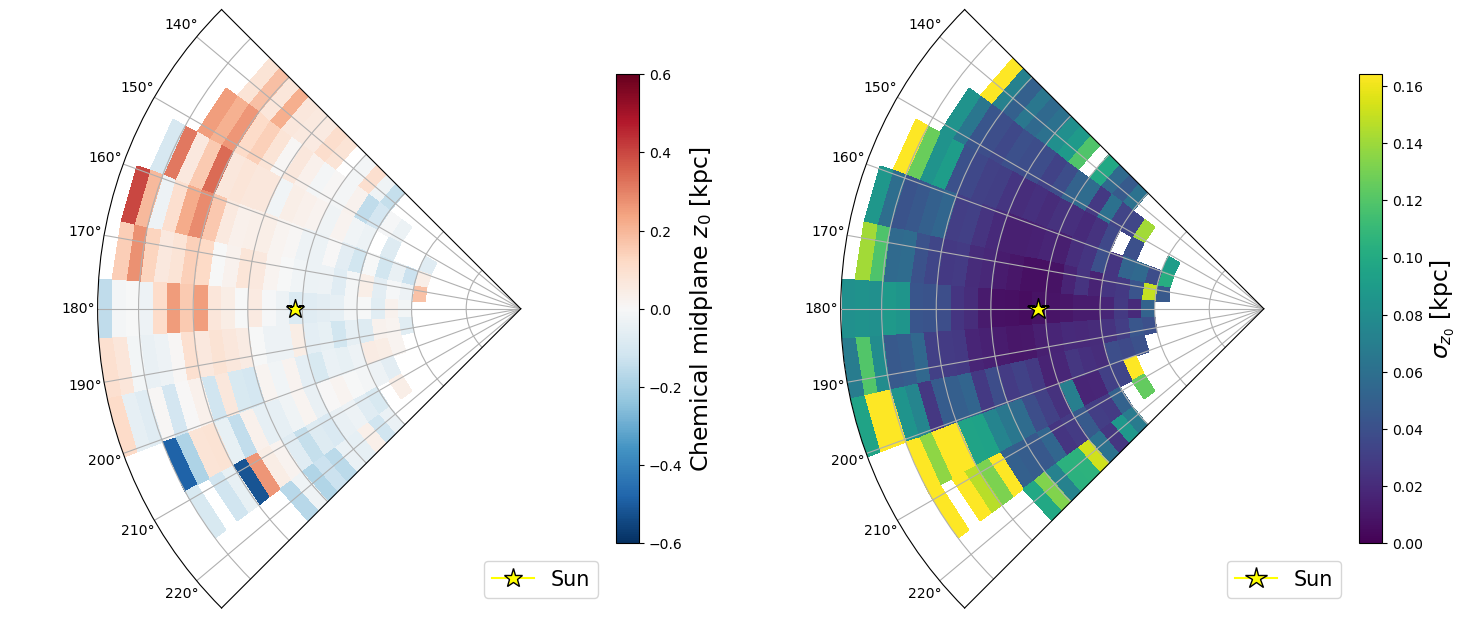

In [13]:
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i - 1]:
        theta_edges[i] += 2 * np.pi

T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
Zmap_med = np.ma.masked_invalid(z0_med)
Zmap_std = np.ma.masked_invalid(z0_std)
std_max = float(np.nanpercentile(z0_std[np.isfinite(z0_std)], 95)) if np.isfinite(z0_std).any() else 1.0
theta_min, theta_max = theta_edges[0], theta_edges[-1]
theta_sun, R_sun = np.radians(180), 8.275

fig = plt.figure(figsize=(15, 7))
ax1 = plt.subplot(1, 2, 1, projection="polar")
pcm1 = ax1.pcolormesh(T_mesh, R_mesh, Zmap_med, cmap="RdBu_r", vmin=-zlim, vmax=zlim, shading="flat")
fig.colorbar(pcm1, ax=ax1, pad=0.01, shrink=0.7).set_label(r"Chemical midplane $z_0$ [kpc]", fontsize=17)
ax1.set_theta_zero_location("E"); ax1.set_theta_direction(1); ax1.set_rmax(R_edges[-1])
ax1.set_thetamin(np.degrees(theta_min)); ax1.set_thetamax(np.degrees(theta_max))
ax1.set_yticklabels([])
ax1.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14, markeredgecolor="k", zorder=5, label="Sun")
ax1.legend(loc="lower right", fontsize=15)

ax2 = plt.subplot(1, 2, 2, projection="polar")
pcm2 = ax2.pcolormesh(T_mesh, R_mesh, Zmap_std, cmap="viridis", vmin=0.0, vmax=std_max, shading="flat")
fig.colorbar(pcm2, ax=ax2, pad=0.01, shrink=0.7).set_label(r"$\sigma_{z_0}$ [kpc]", fontsize=17)
ax2.set_theta_zero_location("E"); ax2.set_theta_direction(1); ax2.set_rmax(R_edges[-1])
ax2.set_thetamin(np.degrees(theta_min)); ax2.set_thetamax(np.degrees(theta_max))
ax2.set_yticklabels([])
ax2.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=16, markeredgecolor="k", zorder=5, label="Sun")
ax2.legend(loc="lower right", fontsize=15)
plt.tight_layout()
plt.show()

fitting radial bins:   0%|                               | 0/23 [00:00<?, ?it/s]/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_17967/2600209016.py:10: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_17967/2600209016.py:11: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_17967/2600209016.py:18: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(
fitting radial bins: 100%|██████████████████████| 23/23 [00:36<00:00,  1.58s/it]


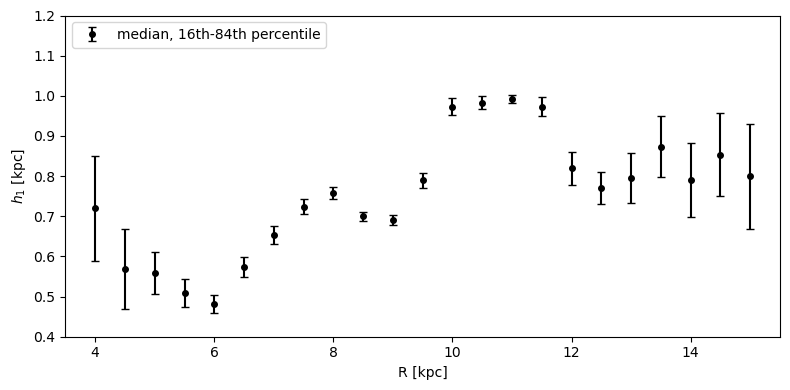

In [20]:
R_centers_flare = np.arange(4, 15 + 1e-3, 0.5)
R_width = 1.0
n_R_flare = len(R_centers_flare)

R_arr, Z_arr, mgfe_arr, err_arr = map(np.asarray, (R_star, Z_star, mgfe_star, mgfe_err_star))
m_base = (np.isfinite(R_arr) & np.isfinite(Z_arr) & np.isfinite(mgfe_arr)
          & np.isfinite(err_arr) & (err_arr > 0))

per_R_flare = {}
key = jr.PRNGKey(0)

for i_R in tqdm(range(n_R_flare), desc="fitting radial bins"):
    Rlo, Rhi = R_centers_flare[i_R] - R_width/2, R_centers_flare[i_R] + R_width/2
    m = m_base & (R_arr >= Rlo) & (R_arr < Rhi)
    n_stars = int(m.sum())
    if n_stars < minN_seg_total:
        continue

    z_binc, mean_mg_fe, mean_mg_fe_err, counts = bin_one(Z_arr[m], mgfe_arr[m], err_arr[m])
    good = (np.isfinite(mean_mg_fe) & np.isfinite(mean_mg_fe_err)
            & (counts >= min_bin_count) & (z_binc >= z_fit_min) & (z_binc <= z_fit_max))
    if good.sum() < min_bins_for_fit:
        continue

    try:
        key, sub = jr.split(key)
        sampler = fit_sech2(np.asarray(z_binc[good], float), np.asarray(mean_mg_fe[good], float),
                             np.asarray(mean_mg_fe_err[good], float), sub, progress_bar=False)
        samples = sampler.get_samples()
        per_R_flare[i_R] = {"Rlo": Rlo, "Rhi": Rhi, "n_stars": n_stars,
                             "z_binc": np.asarray(z_binc[good]), "mean": np.asarray(mean_mg_fe[good]),
                             "err": np.asarray(mean_mg_fe_err[good]),
                             "samples": {k: np.asarray(v) for k, v in samples.items()}}
    except Exception as e:
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: fit failed -> {e}")

with open("per_R_flare_zsun0_1comp.pkl", "wb") as f:
    pickle.dump(per_R_flare, f)

h_eff_med_flare = np.full(n_R_flare, np.nan)
h_eff_std_flare = np.full(n_R_flare, np.nan)

for i_R, cell in per_R_flare.items():
    h1_draws = cell["samples"]["h1"]
    h_eff_med_flare[i_R] = np.median(h1_draws)
    pcl = np.percentile(h1_draws, [16, 84])
    h_eff_std_flare[i_R] = 0.5 * (pcl[1] - pcl[0])
    
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers_flare, h_eff_med_flare, yerr=h_eff_std_flare,
            fmt="o", color="k", ms=4, capsize=3, label="median, 16th-84th percentile")
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{1}$ [kpc]")
ax.set_xlim(R_centers_flare[0] - R_width/2, R_centers_flare[-1] + R_width/2)
ax.set_ylim(0.4,1.2)
plt.tight_layout()
plt.show()

fitting radial bins:   0%|                               | 0/23 [00:00<?, ?it/s]/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_17967/2600209016.py:10: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_17967/2600209016.py:11: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_17967/2600209016.py:18: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(
fitting radial bins: 100%|██████████████████████| 23/23 [00:32<00:00,  1.43s/it]


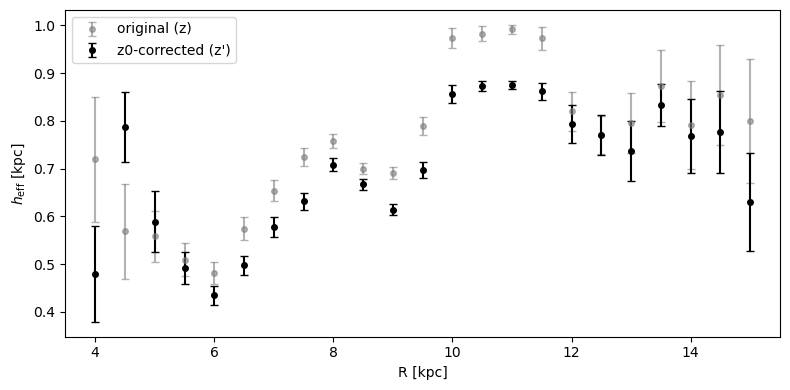

In [25]:
# --- build z0-corrected z' (unchanged) ---
n_R, n_seg = len(R_edges) - 1, len(SEG_PLOT_heat)

Z_prime_star = np.full(len(Z_star), np.nan)
for i_R in range(n_R):
    Rmin, Rmax = float(R_edges[i_R]), float(R_edges[i_R + 1])
    R_mask = (R_star >= Rmin) & (R_star < Rmax)
    for j_seg in range(n_seg):
        if not ok_grid[i_R, j_seg]:
            continue
        seg_id = SEG_PLOT_heat[j_seg]
        m = R_mask & segm[seg_id]
        Z_prime_star[m] = Z_star[m] - z0_med[i_R, j_seg]

# --- flare fit on z' (unchanged, just uses the single-component `model` now) ---
R_centers_flare = np.arange(4, 15 + 1e-3, 0.5)
R_width = 1.0
n_R_flare = len(R_centers_flare)

R_arr, Z_arr, mgfe_arr, err_arr = map(np.asarray, (R_star, Z_prime_star, mgfe_star, mgfe_err_star))
m_base = (np.isfinite(R_arr) & np.isfinite(Z_arr) & np.isfinite(mgfe_arr)
          & np.isfinite(err_arr) & (err_arr > 0))

per_R_flare = {}
key = jr.PRNGKey(0)

for i_R in tqdm(range(n_R_flare), desc="fitting radial bins"):
    Rlo, Rhi = R_centers_flare[i_R] - R_width/2, R_centers_flare[i_R] + R_width/2
    m = m_base & (R_arr >= Rlo) & (R_arr < Rhi)
    n_stars_bin = int(m.sum())
    if n_stars_bin < minN_seg_total:
        continue

    z_binc, mean_mg_fe, mean_mg_fe_err, counts = bin_one(Z_arr[m], mgfe_arr[m], err_arr[m])
    good = (np.isfinite(mean_mg_fe) & np.isfinite(mean_mg_fe_err)
            & (counts >= min_bin_count) & (z_binc >= z_fit_min) & (z_binc <= z_fit_max))
    if good.sum() < min_bins_for_fit:
        continue

    try:
        key, sub = jr.split(key)
        sampler = fit_sech2(np.asarray(z_binc[good], float), np.asarray(mean_mg_fe[good], float),
                             np.asarray(mean_mg_fe_err[good], float), sub, progress_bar=False)
        samples = sampler.get_samples()
        per_R_flare[i_R] = {"Rlo": Rlo, "Rhi": Rhi, "n_stars": n_stars_bin,
                             "z_binc": np.asarray(z_binc[good]), "mean": np.asarray(mean_mg_fe[good]),
                             "err": np.asarray(mean_mg_fe_err[good]),
                             "samples": {k: np.asarray(v) for k, v in samples.items()}}
    except Exception as e:
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: fit failed -> {e}")

with open("per_R_flare_zsun0_z0corr_1comp.pkl", "wb") as f:
    pickle.dump(per_R_flare, f)

# --- h1/HWHM extraction, single-component (replaces root_func/brentq block) ---
HWHM_FACTOR = np.arccosh(np.sqrt(2))  # drop this and use raw h1 if you'd rather

h_eff_med_flare_z0corr = np.full(n_R_flare, np.nan)
h_eff_std_flare_z0corr = np.full(n_R_flare, np.nan)

for i_R, cell in per_R_flare.items():
    hwhm_draws = HWHM_FACTOR * cell["samples"]["h1"]
    h_eff_med_flare_z0corr[i_R] = np.median(hwhm_draws)
    pcl = np.percentile(hwhm_draws, [16, 84])
    h_eff_std_flare_z0corr[i_R] = 0.5 * (pcl[1] - pcl[0])

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers_flare, h_eff_med_flare, yerr=h_eff_std_flare,
            fmt="o", color="gray", ms=4, capsize=3, alpha=0.6, label="original (z)")
ax.errorbar(R_centers_flare, h_eff_med_flare_z0corr, yerr=h_eff_std_flare_z0corr,
            fmt="o", color="k", ms=4, capsize=3, label="z0-corrected (z')")
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{eff}$ [kpc]" if True else r"$h_1$ [kpc]")
ax.set_xlim(R_centers_flare[0] - R_width/2, R_centers_flare[-1] + R_width/2)
plt.tight_layout()
plt.show()

In [26]:
RESULTS_PATH_H1 = "sech2_mcmc_results_zsun0_h1corr.pkl"
FORCE_RERUN_H1 = True

HWHM_FACTOR = np.arccosh(np.sqrt(2))  # drop this and use raw h1 samples if you'd rather

if os.path.exists(RESULTS_PATH_H1) and not FORCE_RERUN_H1:
    with open(RESULTS_PATH_H1, "rb") as f:
        saved = pickle.load(f)
    h1_med_corr, h1_std_corr = saved["h1_med"], saved["h1_std"]
    ok_grid_h1, per_cell_h1 = saved["ok_grid"], saved["per_cell"]
else:
    n_R, n_seg = len(R_edges) - 1, len(SEG_PLOT_heat)
    h1_med_corr = np.full((n_R, n_seg), np.nan)
    h1_std_corr = np.full((n_R, n_seg), np.nan)
    ok_grid_h1  = np.zeros((n_R, n_seg), dtype=bool)
    per_cell_h1 = {}

    key = jr.PRNGKey(0)
    pairs = list(product(range(n_R), range(n_seg)))

    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin, Rmax = float(R_edges[i_R]), float(R_edges[i_R + 1])
        seg_id = SEG_PLOT_heat[j_seg]
        z_binc_k, mean_k, err_k, ns_k, ok_k = select_annulus_segment(
            R_star, Z_prime_star, mgfe_star, mgfe_err_star, seg_mask=segm[seg_id], Rmin=Rmin, Rmax=Rmax)
        if not ok_k:
            continue
        try:
            key, sub = jr.split(key)
            sampler_k = fit_sech2(z_binc_k, mean_k, err_k, sub, progress_bar=False)
            samples_k = sampler_k.get_samples()
            hwhm_draws = HWHM_FACTOR * samples_k["h1"]
            h1_med_corr[i_R, j_seg] = float(np.median(hwhm_draws))
            h1_std_corr[i_R, j_seg] = float(np.std(hwhm_draws))
            ok_grid_h1[i_R, j_seg] = True
            per_cell_h1[(i_R, j_seg)] = {
                "z_binc": np.asarray(z_binc_k), "mean": np.asarray(mean_k), "err": np.asarray(err_k),
                "samples": {kk: np.asarray(vv[:1000]) for kk, vv in samples_k.items()},
            }
        except Exception as e:
            print(f"  fit failed: seg={seg_id} R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")
        if k % 10 == 0 or k == len(pairs):
            print(f"  done {k}/{len(pairs)}", flush=True)

    print("fits complete:", int(ok_grid_h1.sum()), "/", ok_grid_h1.size)
    with open(RESULTS_PATH_H1, "wb") as f:
        pickle.dump({"h1_med": h1_med_corr, "h1_std": h1_std_corr,
                     "ok_grid": ok_grid_h1, "per_cell": per_cell_h1,
                     "R_edges": R_edges, "SEG_PLOT_heat": SEG_PLOT_heat,
                     "crowd_bounds": np.asarray(crowd_bounds)}, f)
    print(f"saved to {RESULTS_PATH_H1}")

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_17967/2600209016.py:10: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_17967/2600209016.py:11: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_17967/2600209016.py:18: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


  done 70/330
  done 130/330
  done 140/330
  done 150/330
  done 160/330
  done 170/330
  done 180/330
  done 190/330
  done 200/330
  done 210/330
  done 220/330
  done 230/330
  done 240/330
  done 250/330
  done 260/330
  done 270/330
  done 280/330
  done 290/330
  done 300/330
fits complete: 204 / 330
saved to sech2_mcmc_results_zsun0_h1corr.pkl


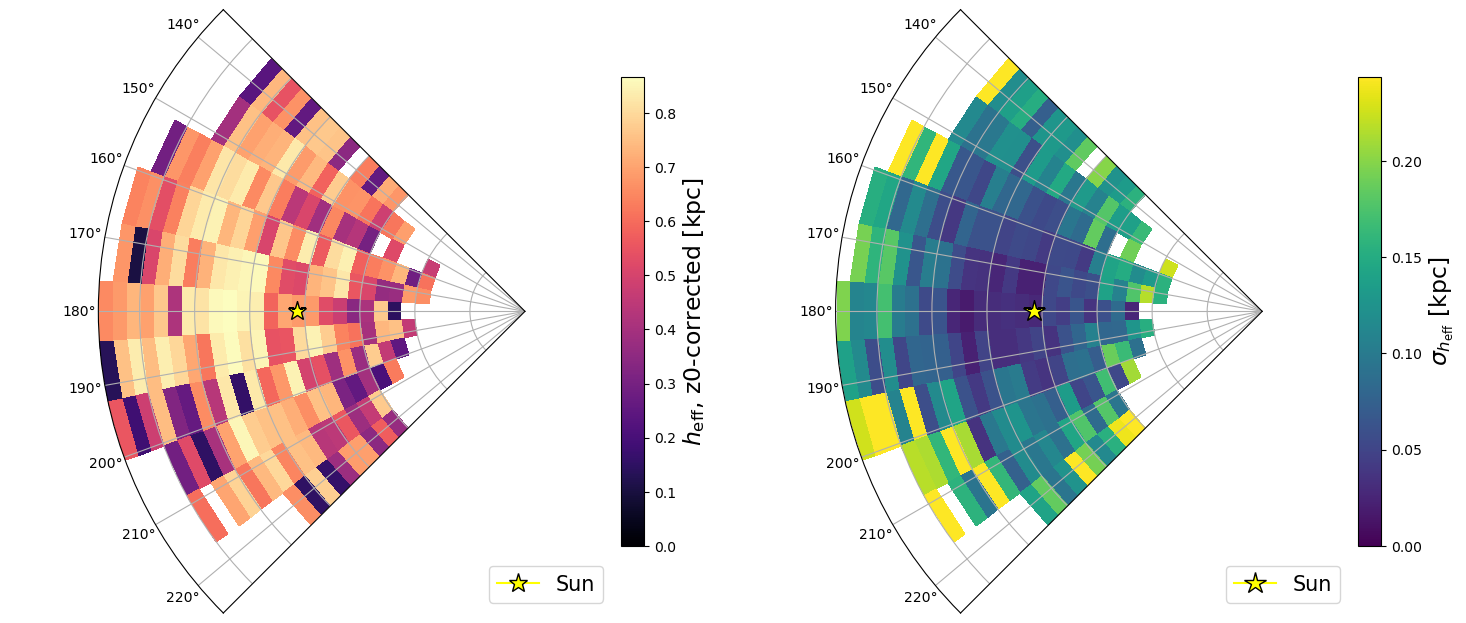

In [28]:
Hmap_med = np.ma.masked_invalid(h1_med_corr)
hlim = float(np.nanmax(h1_med_corr)) if np.isfinite(h1_med_corr).any() else 1.0

fig = plt.figure(figsize=(15, 7))
ax1 = plt.subplot(1, 2, 1, projection="polar")
pcm1 = ax1.pcolormesh(T_mesh, R_mesh, Hmap_med, cmap="magma", vmin=0.0, vmax=hlim, shading="flat")
fig.colorbar(pcm1, ax=ax1, pad=0.01, shrink=0.7).set_label(r"$h_\mathrm{eff}$, z0-corrected [kpc]", fontsize=17)
ax1.set_theta_zero_location("E"); ax1.set_theta_direction(1); ax1.set_rmax(R_edges[-1])
ax1.set_thetamin(np.degrees(theta_min)); ax1.set_thetamax(np.degrees(theta_max))
ax1.set_yticklabels([])
ax1.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14, markeredgecolor="k", zorder=5, label="Sun")
ax1.legend(loc="lower right", fontsize=15)

Hmap_std = np.ma.masked_invalid(h1_std_corr)
std_max_h1 = float(np.nanpercentile(h1_std_corr[np.isfinite(h1_std_corr)], 95)) if np.isfinite(h1_std_corr).any() else 1.0
ax2 = plt.subplot(1, 2, 2, projection="polar")
pcm2 = ax2.pcolormesh(T_mesh, R_mesh, Hmap_std, cmap="viridis", vmin=0.0, vmax=std_max_h1, shading="flat")
fig.colorbar(pcm2, ax=ax2, pad=0.01, shrink=0.7).set_label(r"$\sigma_{h_\mathrm{eff}}$ [kpc]", fontsize=17)
ax2.set_theta_zero_location("E"); ax2.set_theta_direction(1); ax2.set_rmax(R_edges[-1])
ax2.set_thetamin(np.degrees(theta_min)); ax2.set_thetamax(np.degrees(theta_max))
ax2.set_yticklabels([])
ax2.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=16, markeredgecolor="k", zorder=5, label="Sun")
ax2.legend(loc="lower right", fontsize=15)
plt.tight_layout()
plt.show()